# CheMeleon experiment

- **Regression:** predict how strongly a molecule inhibits four enzymes: CYP1A2, CYP2C9, CYP2D6 and CYP3A4
- **Classification:** predict whether a molecule shows time dependent inhibition for CYP2D6 and CYP3A4

CheMeleon reads a molecule as an atom–bond graph.
Its pretrained encoder produces features, and our MLP head turns those features into predictions and we train one model per task.

## Loading experiment results

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [2]:
results_dir = Path("notebooks/results/chemeleon")
if Path.cwd().name == "notebooks":
    results_dir = Path("results/chemeleon")

experiments = pd.read_csv(results_dir / "experiments.csv")
with open(results_dir / "test_metrics_regresion.json") as file:
    regression_test = json.load(file)
with open(results_dir / "test_metrics_classification.json") as file:
    classification_test = json.load(file)

print("Saved experiment runs:", len(experiments))
display(experiments.groupby(["run_kind", "task"]).size().unstack(fill_value=0))

Saved experiment runs: 40


task,classification,regression
run_kind,,
evaluating,1,1
experimenting,15,15
repeat,2,0
seed_check,6,0


The experiments csv file contains 40 completed runs, where we have labeled the purpose of each run as:
- experimenting: the default seed 42 experiment that has slightly adjusted some config
- repeating run of a confing
- seed-check: a repeat experiment but with just the seed changed to 43 or 44.
- evaluating: training of an existing experiment with test evaluation enabled

And also these values are not included in the csv file since they are always the same in the experiments:
- grad_clip: the max gradient norm was 1 in everything
- num_layers: MLP used 3 linear layers (2 hidden & 1 output), and linear readout does not have it
- lr_factor: When learning-rate scheduling was enabled, the factor was 0.5 to half the learning rate. Otherwise it was null.

## Validation scores

- Regression: MA-ST-RAE (the mean ST-RAE over 4 enzymes), where Lower is better
- Classification: Mean MCC over 2 enzymes, here Higher is better

We first make one table of regression scores and another of classification scores. `merge` matches them by configuration name. `how="outer"` keeps a configuration even when only one task has a result; the other score is then missing.

In [3]:
experiment_runs = experiments[experiments["run_kind"] == "experimenting"].copy()

regression_scores = experiment_runs[experiment_runs["task"] == "regression"]
regression_scores = regression_scores[["configuration", "best_validation_score"]]
regression_scores = regression_scores.rename(
    columns={"best_validation_score": "Regression (MA-ST-RAE)"}
)
classification_scores = experiment_runs[experiment_runs["task"] == "classification"]
classification_scores = classification_scores[["configuration", "best_validation_score"]]
classification_scores = classification_scores.rename(
    columns={"best_validation_score": "Classification (MCC)"}
)

# Match configuration names and keep configurations tested for either task.
comparison = regression_scores.merge(classification_scores, on="configuration", how="outer")
comparison = comparison.set_index("configuration")
comparison = comparison.reindex(experiment_runs["configuration"].drop_duplicates())

display(comparison.round(4).fillna("—"))
print("Configurations:", len(comparison))
print("Experimenting runs:", len(experiment_runs))

,Regression (MA-ST-RAE),Classification (MCC)
configuration,,
Frozen encoder,0.7123,0.2367
Full fine-tuning,0.7037,0.2998
Encoder learning rate 3e-6,0.7175,0.2647
MLP width 256,0.7231,0.293
"Linear head, 20 epochs",0.7246,0.2188
Dropout 0.3,0.7054,0.2811
"MLP, 40 epochs",—,0.2661
"Linear head, 40 epochs",—,0.2716
Head LR 3e-4 + dropout 0.3,0.7192,—


Configurations: 17
Experimenting runs: 30


17 configurations.

There's 30 experiment runs, 15 each. And an empty value means a config was not tested for classification/regression.

Most settings change one part of the full fine-tuning reference.

The following sections show plots and rank these original experiment runs.

## Regression config results

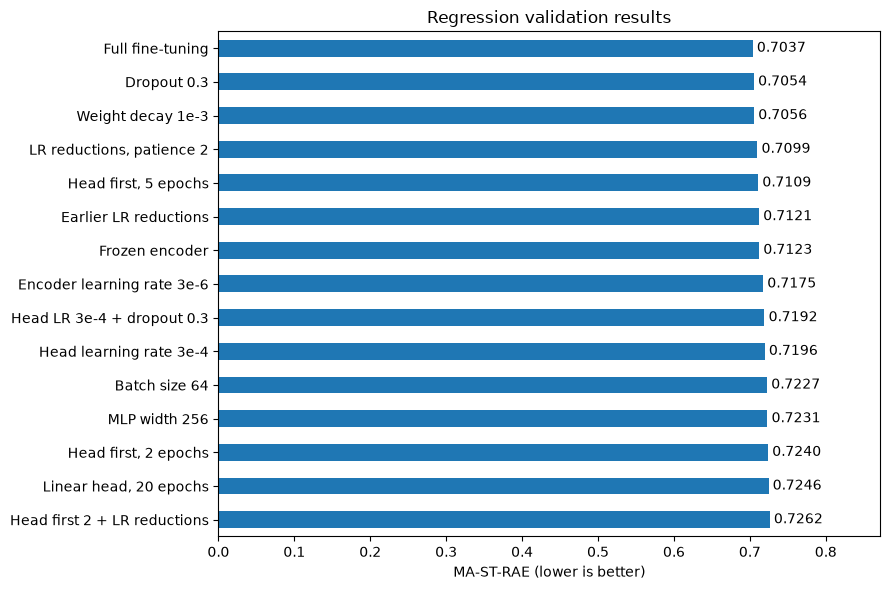

In [4]:
regression = experiment_runs[experiment_runs["task"] == "regression"].sort_values(
    "best_validation_score"
)

ax = regression.plot.barh(
    x="configuration", y="best_validation_score", legend=False, figsize=(9, 6)
)
ax.invert_yaxis()
ax.set_xlim(0, regression["best_validation_score"].max() * 1.2)
ax.set_title("Regression validation results")
ax.set_xlabel("MA-ST-RAE (lower is better)")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], fmt="%.4f", padding=3)
plt.tight_layout()
plt.show()

## Classification config results

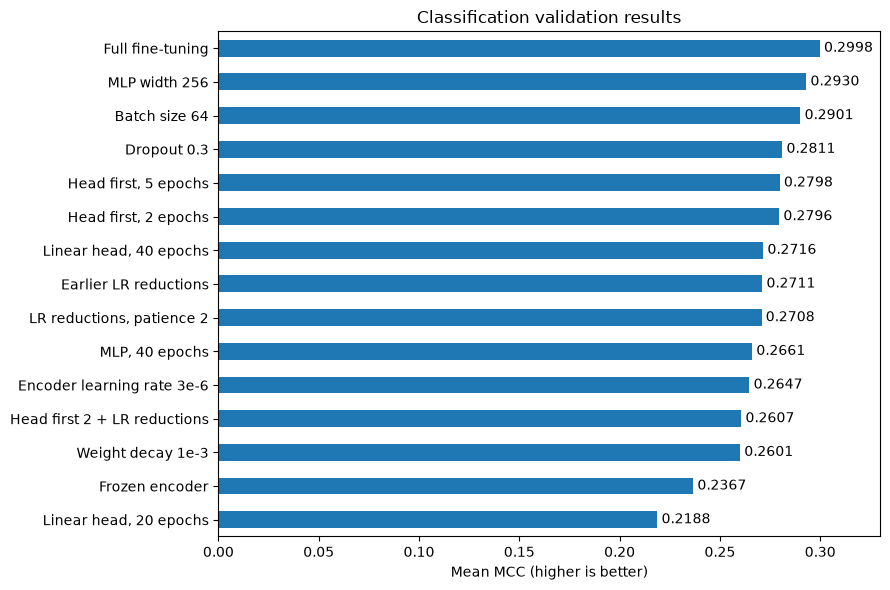

In [5]:
classification = experiment_runs[experiment_runs["task"] == "classification"].sort_values(
    "best_validation_score", ascending=False
)

ax = classification.plot.barh(
    x="configuration", y="best_validation_score", legend=False, figsize=(9, 6)
)
ax.invert_yaxis()
ax.set_xlim(0, classification["best_validation_score"].max() * 1.1)
ax.set_title("Classification validation results")
ax.set_xlabel("Mean MCC (higher is better)")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], fmt="%.4f", padding=3)
plt.tight_layout()
plt.show()

## Variation between runs

In [6]:
reference_runs = experiments[
    (experiments["task"] == "classification") & (experiments["configuration"] == "Full fine-tuning")
]

display(
    reference_runs[["seed", "run_kind", "best_validation_score", "best_epoch"]]
    .reset_index(drop=True)
    .round(4)
)

,seed,run_kind,best_validation_score,best_epoch
0,42,experimenting,0.2998,16
1,42,repeat,0.2689,13
2,43,seed_check,0.2768,9
3,44,seed_check,0.2907,7
4,42,evaluating,0.2636,19


## Record the selected settings

We used full fine-tuning with the original MLP recipe for both tasks.

The table below shows the actual recorded settings of the 2 models used for the reported test results.

In [7]:
test_runs = experiments[experiments["run_kind"] == "evaluating"].copy()
selected_columns = [
    "seed",
    "freeze_encoder",
    "readout_type",
    "hidden_dim",
    "dropout",
    "encoder_lr",
    "head_lr",
    "batch_size",
    "weight_decay",
    "epochs",
    "head_only_epochs",
    "reduce_lr",
]

display(test_runs.set_index("task")[selected_columns].T)

task,classification,regression
seed,42,42
freeze_encoder,False,False
readout_type,mlp,mlp
hidden_dim,512.0,512.0
dropout,0.1,0.1
encoder_lr,0.00001,0.00001
head_lr,0.001,0.001
batch_size,32,32
weight_decay,0.0001,0.0001
epochs,20,20


In [8]:
display(
    test_runs[["task", "seed", "best_epoch", "best_validation_score", "test_score"]]
    .reset_index(drop=True)
    .round(4)
)

,task,seed,best_epoch,best_validation_score,test_score
0,classification,42,19,0.2636,0.1860
1,regression,42,4,0.7047,0.7376


## Regression test result (MA-ST-RAE)

In [9]:
regression_score = regression_test["macro_ST-RAE"]
regression_by_enzyme = regression_test.copy()
regression_by_enzyme.pop("macro_ST-RAE")

display(pd.DataFrame.from_dict(regression_by_enzyme, orient="index").round(4))
print(f"MA-ST-RAE: {regression_score:.4f}")

,MAE,R2,ST-RAE,n
CYP1A2_pIC50_direct_inhibition,0.6070,0.3014,0.7942,229
CYP2C9_pIC50_direct_inhibition,0.4737,0.3252,0.7202,199
CYP2D6_pIC50_direct_inhibition,0.6122,0.1269,0.9264,222
CYP3A4_pIC50_direct_inhibition,0.6114,0.5079,0.5097,374


MA-ST-RAE: 0.7376


## Classification test result (MCC)

In [10]:
classification_score = classification_test["macro_MCC"]
classification_by_enzyme = classification_test.copy()
classification_by_enzyme.pop("macro_MCC")

classification_table = pd.DataFrame.from_dict(classification_by_enzyme, orient="index")
classification_table = classification_table.drop(columns="Accuracy", errors="ignore")
display(classification_table.round(4))
print(f"Mean MCC: {classification_score:.4f}")

,MCC,AUROC,AP,n,positive_fraction
CYP2D6_is_TDI,0.0391,0.5023,0.2874,222,0.2568
CYP3A4_is_TDI,0.3328,0.7603,0.4560,536,0.2220


Mean MCC: 0.1860
